1.Restauration (monter Drive + dézipper)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = "/content/drive/MyDrive/projet_auto_cnn"

# dézipper les images augmentées dans /content/aug
!mkdir -p /content/aug
!unzip -q -o {SAVE_DIR}/aug.zip -d /content/aug

import os
print(len(os.listdir("/content/aug")), "images augmentées restaurées")

Mounted at /content/drive
877 images augmentées restaurées


2.Retélécharge les photos originale(kagglehub.dataset_download)

In [ ]:
import kagglehub
path = kagglehub.dataset_download("infernape/fast-furious-and-insured")
print(path)

100%|██████████| 104M/104M [00:05<00:00, 18.5MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/infernape/fast-furious-and-insured/versions/1


3.Bibliothèques

In [ ]:
# importer les bibliothèques
import os, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

tf.keras.utils.set_random_seed(42)
print("TensorFlow :", tf.__version__)

TensorFlow : 2.21.0


4.Charger les trois ensembles et retirer le groupe contradictoire

In [ ]:
import glob

train_cnn = pd.read_csv(f"{SAVE_DIR}/split_train_cnn.csv")
val_df    = pd.read_csv(f"{SAVE_DIR}/split_val.csv")
test_df   = pd.read_csv(f"{SAVE_DIR}/split_test.csv")

# 1) retrouver le dossier des photos originales dans CETTE session
premier = val_df["Image_path"].iloc[0]
trouve  = glob.glob(f"{path}/**/{premier}", recursive=True)
IMG_DIR = os.path.dirname(trouve[0]) + "/"
print("IMG_DIR =", IMG_DIR)

# 2) corriger la colonne chemin des photos originales (les images augmentées gardent /content/aug)
def corriger_chemin(d):
    d = d.copy()
    originales = ~d["chemin"].str.startswith("/content/aug")
    d.loc[originales, "chemin"] = IMG_DIR + d.loc[originales, "Image_path"]
    return d

train_cnn, val_df, test_df = corriger_chemin(train_cnn), corriger_chemin(val_df), corriger_chemin(test_df)

# 3) retirer les 2 images à étiquettes contradictoires (sécurité, normalement 0)
CONFLITS = ["img_4514696.jpg", "img_7766946.jpg"]
def nettoyer(d):
    sortie = d[~d["Image_path"].isin(CONFLITS)]
    if "origine" in d.columns:
        sortie = sortie[~sortie["origine"].isin(CONFLITS)]
    return sortie.reset_index(drop=True)

for nom, d in [("train", train_cnn), ("val", val_df), ("test", test_df)]:
    print(f"{nom:5s} avant : {len(d)} | retirées : {len(d) - len(nettoyer(d))}")
train_cnn, val_df, test_df = nettoyer(train_cnn), nettoyer(val_df), nettoyer(test_df)

# 4) vérifier que toutes les images existent
for nom, d in [("train", train_cnn), ("val", val_df), ("test", test_df)]:
    manquantes = (~d["chemin"].apply(os.path.exists)).sum()
    print(f"{nom:5s} {len(d):4d} images | introuvables : {manquantes} | classes :", d["Condition"].value_counts().to_dict())

train avant : 1876 | retirées : 0
val   avant : 199 | retirées : 0
test  avant : 199 | retirées : 0
train 1876 images | introuvables : 999 | classes : {0: 938, 1: 938}
val    199 images | introuvables : 199 | classes : {1: 175, 0: 24}
test   199 images | introuvables : 199 | classes : {1: 186, 0: 13}


Introuvables = le nombre de lignes du tableau dont le fichier image n’existe pas à l’adresse écrite dans la colonne chemin.

Le code teste chaque ligne avec os.path.exists(chemin). Si le fichier est là, c’est « trouvé ». S’il n’y est pas, il est compté comme « introuvable ».

0 introuvable : toutes les images sont accessibles, on peut les charger.
Plus de 0 : le tableau pointe vers des photos absentes, et le chargement échouera.

Chez vous, il y en avait 999 en train, 199 en validation et 199 en test. C’étaient toutes les photos originales : leur adresse enregistrée datait de l’ancienne session. Les photos existaient bien, mais ailleurs, d’où la correction du chemin.

Pour une phrase à mettre dans le notebook : « Introuvables : nombre d’images dont le fichier n’existe pas à l’emplacement indiqué ; doit être égal à 0. »

5.Charger et redimensionner les images en tableaux numpy

In [ ]:
IMG_SIZE = 128

def corriger_chemin(chemin, local_path):
    # Si le chemin commence par le dossier Kaggle d'origine, on le redirige vers le cache kagglehub
    cle = "/kaggle/input/fast-furious-and-insured"
    if isinstance(chemin, str) and chemin.startswith(cle):
        return chemin.replace(cle, local_path)
    return chemin

# Corriger les chemins dans les dataframes avant de charger les images
for df in [train_cnn, val_df, test_df]:
    df["chemin"] = df["chemin"].apply(lambda x: corriger_chemin(x, path))

def charger_images(d):
    X = np.zeros((len(d), IMG_SIZE, IMG_SIZE, 3), dtype='uint8')
    for i, chemin in enumerate(d["chemin"]):
        with Image.open(chemin) as im:
            X[i] = np.array(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
    return X

X_train = charger_images(train_cnn); y_train = train_cnn["Condition"].values
X_val   = charger_images(val_df);    y_val   = val_df["Condition"].values
X_test  = charger_images(test_df);   y_test  = test_df["Condition"].values

6.Taille des données

In [ ]:
print(X_train.shape, y_train.shape)
print(X_val.shape,   y_val.shape)
print(X_test.shape,  y_test.shape)

(1876, 128, 128, 3) (1876,)
(199, 128, 128, 3) (199,)
(199, 128, 128, 3) (199,)


7.Afficher une image de chaque classe

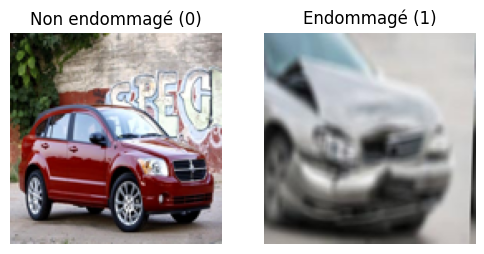

In [ ]:
targets = ['Non endommagé', 'Endommagé']

plt.figure(figsize=(6, 3))
for k, classe in enumerate([0, 1]):
    i = np.where(y_train == classe)[0][0]
    plt.subplot(1, 2, k + 1)
    plt.imshow(X_train[i])
    plt.title(f"{targets[y_train[i]]} ({y_train[i]})")
    plt.axis("off")
plt.show()

8.Normalisation dans [0, 1]

In [ ]:
print('avant :', X_train.dtype, X_train.min(), X_train.max())

X_train = X_train.astype('float32') / 255.0
X_val   = X_val.astype('float32') / 255.0
X_test  = X_test.astype('float32') / 255.0

print('après :', X_train.dtype, X_train.min(), X_train.max())

avant : uint8 0 255
après : float32 0.0 1.0


9.One-hot des labels

In [ ]:
# 0 = (1,0) non endommagé   |   1 = (0,1) endommagé
y_train = tf.one_hot(y_train, depth=2)
y_val   = tf.one_hot(y_val,   depth=2)
y_test  = tf.one_hot(y_test,  depth=2)
print(y_train[0], y_train.shape)

tf.Tensor([1. 0.], shape=(2,), dtype=float32) (1876, 2)


10.Le modèle (3 blocs convolution + pooling)

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    # Bloc 1 : 128x128x3 -> 128x128x32 -> 64x64x32
    tf.keras.layers.Conv2D(32, kernel_size=(5, 5), padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Bloc 2 : 64x64x32 -> 64x64x64 -> 32x32x64
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Bloc 3 : 32x32x64 -> 32x32x128 -> 16x16x128
    tf.keras.layers.Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Flatten : 16*16*128 = 32768
    tf.keras.layers.Flatten(),

    # Classification
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(2, activation='sigmoid')   # 2 classes : non endommagé / endommagé
])

11.Résumé du modèle

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289,474 (16.36 MB)

 Trainable params: 4,289,474 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

12.Compilation

In [ ]:
# 2 classes en one-hot -> categorical_crossentropy
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

13.Entraînement

In [ ]:
history = model.fit(X_train, y_train,
                    epochs=15,
                    batch_size=32,
                    validation_data=(X_val, y_val))

Epoch 1/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 60s 998ms/step - accuracy: 0.6189 - loss: 0.6548 - val_accuracy: 0.8593 - val_loss: 0.5056
Epoch 2/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 51s 864ms/step - accuracy: 0.7505 - loss: 0.5051 - val_accuracy: 0.8593 - val_loss: 0.4150
Epoch 3/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 52s 880ms/step - accuracy: 0.7996 - loss: 0.4300 - val_accuracy: 0.8492 - val_loss: 0.4145
Epoch 4/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 51s 862ms/step - accuracy: 0.8321 - loss: 0.3670 - val_accuracy: 0.8442 - val_loss: 0.4116
Epoch 5/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 82s 857ms/step - accuracy: 0.8619 - loss: 0.3211 - val_accuracy: 0.8191 - val_loss: 0.4349
Epoch 6/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 82s 873ms/step - accuracy: 0.8822 - loss: 0.2755 - val_accuracy: 0.8492 - val_loss: 0.4143
Epoch 7/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 84s 909ms/step - accuracy: 0.9041 - loss: 0.2422 - val_accuracy: 0.8342 - val_loss: 0.4300
Epoch 8/15
59/59 ━━━━━━━━━━━━━━━━━━━━ 80s 872ms/step - accuracy: 0.9152 - loss: 0.2084 - val_accu

14.Courbes d’apprentissage

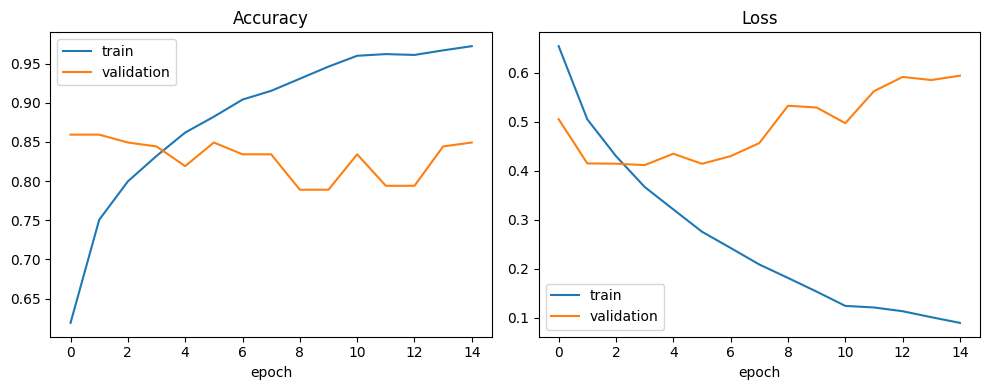

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()

plt.tight_layout(); plt.show()

15.Evaluation sur le test

In [ ]:
loss_and_metrics = model.evaluate(X_test, y_test, verbose=1)
print('test loss =', loss_and_metrics[0])
print('test Accuracy =', loss_and_metrics[1])

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 198ms/step - accuracy: 0.9196 - loss: 0.2907
test loss = 0.29070374369621277
test Accuracy = 0.9195979833602905


16.Prédictions et matrice de confusion

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 391ms/step


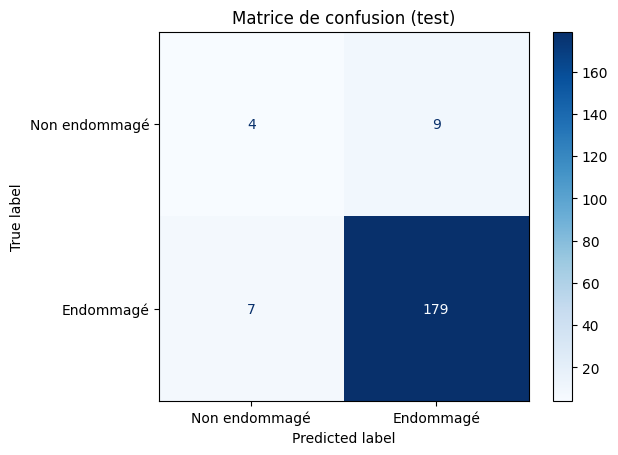

               precision    recall  f1-score   support

Non endommagé       0.36      0.31      0.33        13
    Endommagé       0.95      0.96      0.96       186

     accuracy                           0.92       199
    macro avg       0.66      0.64      0.65       199
 weighted avg       0.91      0.92      0.92       199



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

proba  = model.predict(X_test)
y_pred = np.argmax(proba, axis=1)
y_true = np.argmax(y_test.numpy(), axis=1)

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Non endommagé', 'Endommagé']).plot(cmap='Blues')
plt.title('Matrice de confusion (test)'); plt.show()

print(classification_report(y_true, y_pred, target_names=['Non endommagé', 'Endommagé']))

17.Comparaison avec la référence « toujours endommagé »

In [ ]:
ref = (y_true == 1).mean()
print(f"Référence (toujours 'endommagé') : {ref:.3f}")
print(f"CNN                               : {(y_pred == y_true).mean():.3f}")

Référence (toujours 'endommagé') : 0.935
CNN                               : 0.920


18.Afficher les 6 erreurs

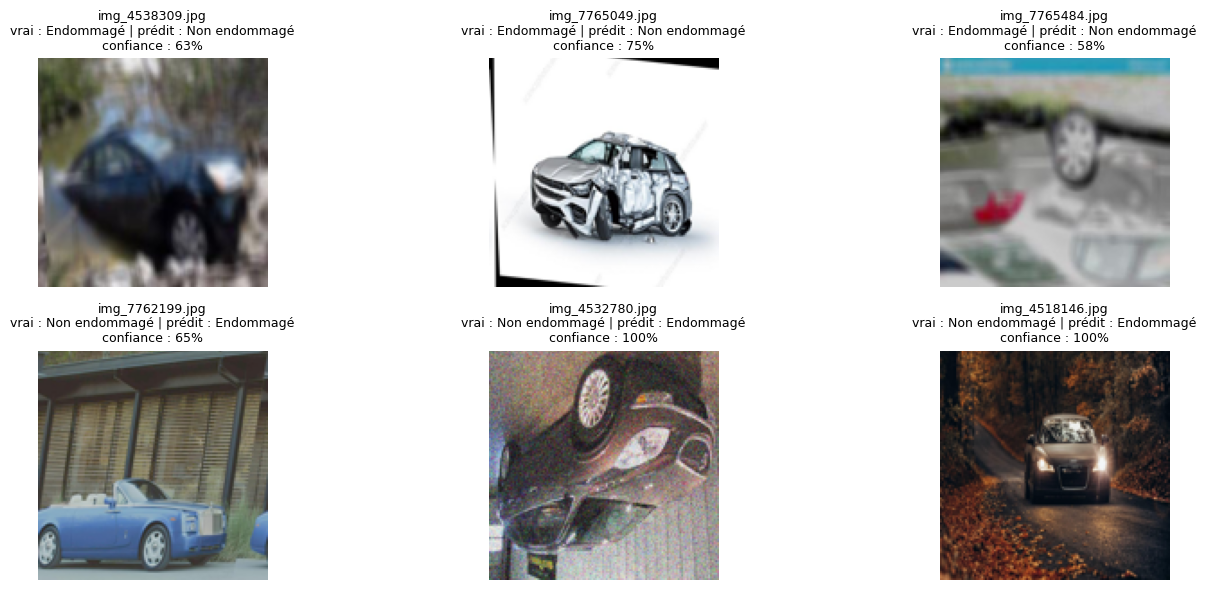

In [ ]:
faux_neg = np.where((y_true == 1) & (y_pred == 0))[0]   # endommagé prédit sain
faux_pos = np.where((y_true == 0) & (y_pred == 1))[0]   # sain prédit endommagé

choix = list(faux_neg[:3]) + list(faux_pos[:3])
if len(choix) < 6:                                       # compléter si une catégorie est trop petite
    autres = [i for i in np.where(y_true != y_pred)[0] if i not in choix]
    choix += autres[:6 - len(choix)]

plt.figure(figsize=(15, 6))
for k, i in enumerate(choix):
    plt.subplot(2, 3, k + 1)
    plt.imshow(X_test[i]); plt.axis("off")
    plt.title(f"{test_df['Image_path'][i]}\nvrai : {targets[y_true[i]]} | prédit : {targets[y_pred[i]]}\n"
              f"confiance : {proba[i].max():.0%}", fontsize=9)
plt.tight_layout(); plt.show()

19.Sauvegarder le modèle pour Streamlit

In [ ]:
model.save(f"{SAVE_DIR}/cnn_auto.keras")